# IBM Quantum Vishnu Institute of Technology

## Qiskit Fall Fest 2026

### Challenge 3: Can You Change the Correlation?

**Objective:** To understand how quantum gates can change the correlation between the measurement outcomes of two qubits.

**Tasks:**

1. Create a two-qubit quantum circuit.
2. Prepare the original Bell state using H and CNOT gates.
3. Modify the circuit by adding one quantum gate.
4. Predict the measurement outcomes before simulation.
5. Measure both qubits and execute the circuit for 100 shots.
6. Display the results using histograms.
7. Compare the original and modified circuits.
8. Explain how the additional gate changes the correlation between the two qubits.


In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc_original = QuantumCircuit(2, 2)

qc_original.h(0)
qc_original.cx(0, 1)

qc_original.measure([0, 1], [0, 1])

print(qc_original.draw())

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


In [2]:
simulator = AerSimulator()

result_original = simulator.run(
    qc_original,
    shots=100
).result()

counts_original = result_original.get_counts()

print("Original Bell-state results:", counts_original)

Original Bell-state results: {'00': 54, '11': 46}


     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


In [4]:
result_modified = simulator.run(
    qc_modified,
    shots=100
).result()

counts_modified = result_modified.get_counts()

print("Modified Bell-state results:", counts_modified)

Modified Bell-state results: {'10': 45, '01': 55}


## Challenge 3: Observations and Conclusion

### Observations

1. The original Bell-state circuit produced the outcomes `00` and `11`, showing that the two qubits had matching measurement results.
2. After adding an X gate to qubit 1, the modified circuit produced the outcomes `01` and `10`.
3. The X gate flipped the target qubit, changing the relationship from matching outcomes to opposite outcomes.
4. In 100 shots, the two allowed outcomes in each circuit appeared approximately 50 times each.

### Conclusion

This experiment demonstrates that quantum gates can change the correlation between two qubits. The original Bell-state circuit, using H and CNOT gates, produced matching outcomes. By adding an X gate to the second qubit, we changed the outcomes to opposite pairs. Thus, a single additional quantum gate can change the measurement correlation without destroying it.


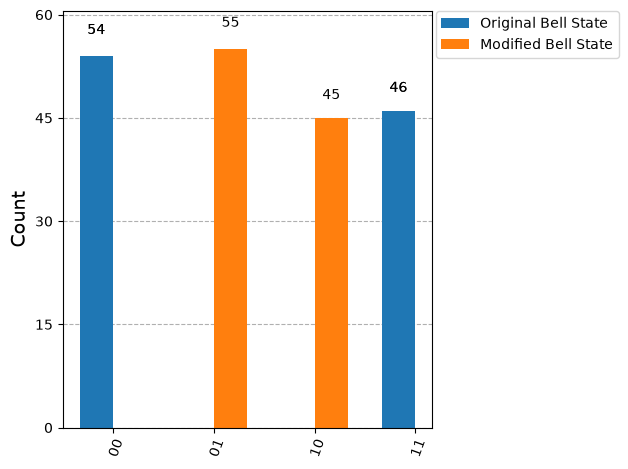

In [5]:
from qiskit.visualization import plot_histogram

plot_histogram(
    [counts_original, counts_modified],
    legend=["Original Bell State", "Modified Bell State"]
)